# License plate detection with YOLO26: evaluation

Test set: 398 images never used during training. The model is read from the output of `01_data_and_training.ipynb`.

In [1]:
!pip install -q -U ultralytics

import os
import glob
import random

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from ultralytics import YOLO

RUN = '/kaggle/input/notebooks/soufiankipsta/yolodetection'
BEST = f'{RUN}/runs/baseline_yolo26s/weights/best.pt'
YOLO_DIR = f'{RUN}/yolo'

print('Test images:', len(os.listdir(f'{YOLO_DIR}/test/images')))
print('Test labels:', len(os.listdir(f'{YOLO_DIR}/test/labels')))

# data.yaml from the training run points to /kaggle/working, so write a new one
with open('/kaggle/working/data_test.yaml', 'w') as f:
    f.write(f"path: {YOLO_DIR}\ntrain: train/images\nval: valid/images\n"
            "test: test/images\nnames:\n  0: License_Plate\n")

model = YOLO(BEST)
m = model.val(data='/kaggle/working/data_test.yaml', split='test', imgsz=640, batch=16,
              project='/kaggle/working/eval', name='test', exist_ok=True, verbose=False)

print(f"\nTEST  Precision {m.box.mp:.3f} | Recall {m.box.mr:.3f} | "
      f"mAP50 {m.box.map50:.3f} | mAP50-95 {m.box.map:.3f}")

Test images: 398
Test labels: 398
Ultralytics 8.4.177 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO26s summary (fused): 120 layers, 9,465,567 parameters, 0 gradients, 20.8 GFLOPs
val: Scanning /kaggle/input/notebooks/soufiankipsta/yolodetection/yolo/test/labels... 398 images, 2 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 398/398 264.4it/s 1.5s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 25/25 4.5it/s 5.6s0.2s
                   all        398        462      0.922      0.892       0.91      0.564
Speed: 0.9ms preprocess, 7.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to /kaggle/working/eval/test

TEST  Precision 0.922 | Recall 0.892 | mAP50 0.910 | mAP50-95 0.564


## Sample predictions

Green = label, dashed red = prediction.

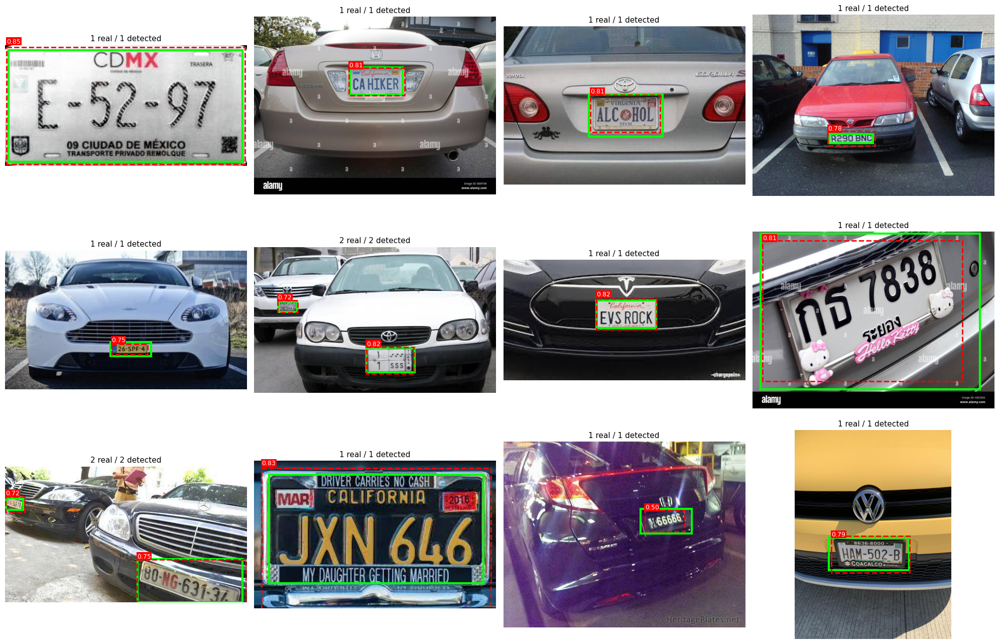

In [2]:
test_imgs = sorted(glob.glob(f'{YOLO_DIR}/test/images/*'))
random.seed(1)
sample = random.sample(test_imgs, 12)


def load_gt(img_path, W, H):
    lbl = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    out = []
    if os.path.exists(lbl):
        for line in open(lbl).read().splitlines():
            if line.strip():
                _, xc, yc, w, h = map(float, line.split())
                out.append(((xc - w / 2) * W, (yc - h / 2) * H, w * W, h * H))
    return out


results = model.predict(sample, conf=0.25, imgsz=640, verbose=False)

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
for ax, path, r in zip(axes.flat, sample, results):
    img = Image.open(path)
    W, H = img.size
    ax.imshow(img)
    for x, y, w, h in load_gt(path, W, H):
        ax.add_patch(patches.Rectangle((x, y), w, h, lw=3, ec='lime', fc='none'))
    for (x1, y1, x2, y2), c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, lw=2, ec='red', fc='none', ls='--'))
        ax.text(x1, y1 - 4, f'{c:.2f}', color='white', fontsize=9, bbox=dict(fc='red', ec='none', pad=1))
    ax.set_title(f'{len(load_gt(path, W, H))} real / {len(r.boxes)} detected', fontsize=11)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Error analysis

A plate counts as missed when no prediction overlaps it with IoU ≥ 0.5.

In [3]:
def gt_xyxy(path, W, H):
    return np.array([[x, y, x + w, y + h] for x, y, w, h in load_gt(path, W, H)]).reshape(-1, 4)


def iou_matrix(a, b):
    if len(a) == 0 or len(b) == 0:
        return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0])
    y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2])
    y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    area_a = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1])
    area_b = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (area_a[:, None] + area_b[None, :] - inter + 1e-9)


rows = []
for path in test_imgs:
    r = model.predict(path, conf=0.25, imgsz=640, verbose=False)[0]
    H, W = r.orig_shape
    gt = gt_xyxy(path, W, H)
    pr = r.boxes.xyxy.cpu().numpy()
    cf = r.boxes.conf.cpu().numpy()
    M = iou_matrix(gt, pr)
    miss = ~(M >= 0.5).any(1) if len(gt) else np.zeros(0, bool)
    fp = ~(M >= 0.5).any(0) if len(pr) else np.zeros(0, bool)
    rel_size = (gt[:, 2] - gt[:, 0]) * (gt[:, 3] - gt[:, 1]) / (W * H) if len(gt) else np.zeros(0)
    rows.append(dict(path=path, gt=gt, pr=pr, cf=cf, miss=miss, fp=fp, rel_size=rel_size))

n_gt = sum(len(r['gt']) for r in rows)
n_miss = sum(r['miss'].sum() for r in rows)
n_fp = sum(r['fp'].sum() for r in rows)
print(f'Plates in test: {n_gt} | Missed: {n_miss} | False alarms: {n_fp}')

sizes_miss = np.concatenate([r['rel_size'][r['miss']] for r in rows if len(r['gt'])])
sizes_ok = np.concatenate([r['rel_size'][~r['miss']] for r in rows if len(r['gt'])])
print(f'Median plate size - found: {np.median(sizes_ok) * 100:.2f}% of image | '
      f'missed: {np.median(sizes_miss) * 100:.2f}% of image')

Plates in test: 462 | Missed: 41 | False alarms: 50
Median plate size - found: 2.25% of image | missed: 0.28% of image


Yellow = missed plate, dashed magenta = false alarm.

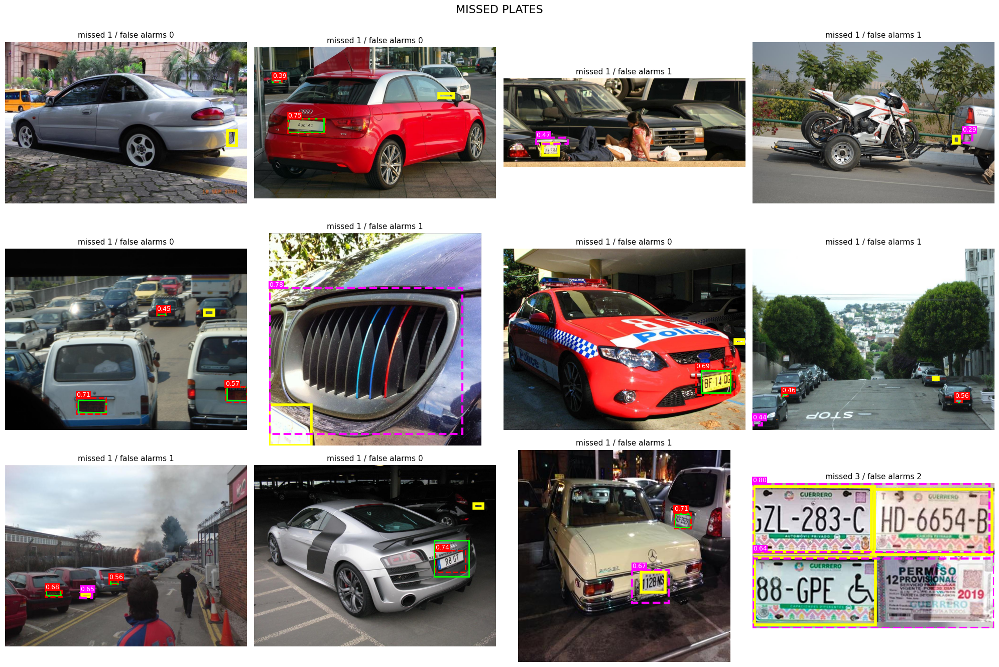

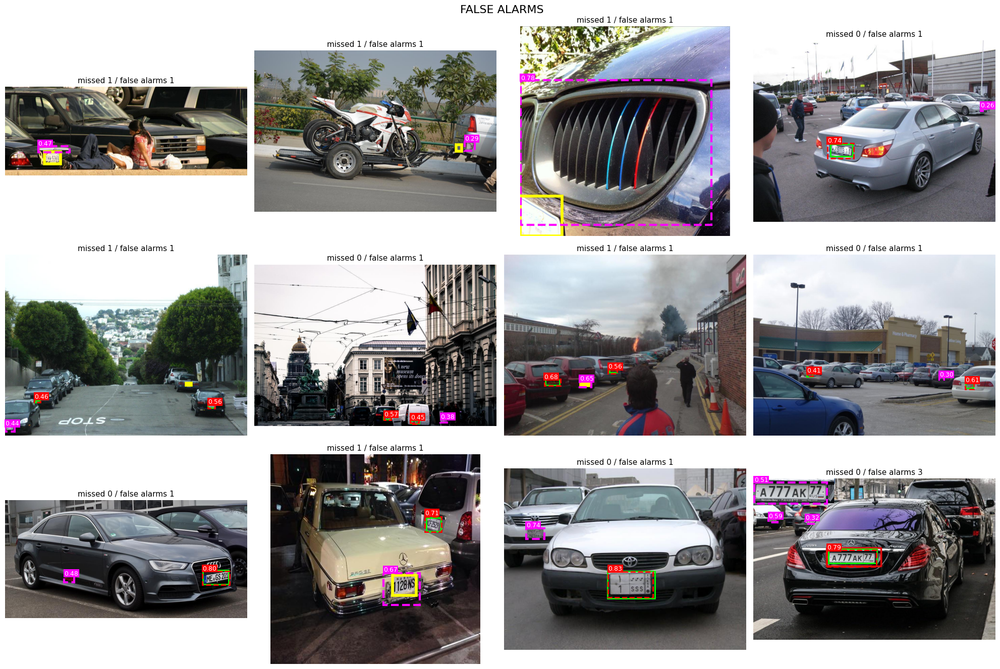

In [4]:
def show_grid(items, title):
    items = items[:12]
    if not items:
        print(f'No {title}')
        return
    n_rows = (len(items) + 3) // 4
    fig, axes = plt.subplots(n_rows, 4, figsize=(20, 4.5 * n_rows))
    for ax in np.atleast_1d(axes).flat:
        ax.axis('off')
    for ax, r in zip(np.atleast_1d(axes).flat, items):
        ax.imshow(Image.open(r['path']))
        for b, missed in zip(r['gt'], r['miss']):
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                                           lw=4 if missed else 2, ec='yellow' if missed else 'lime', fc='none'))
        for b, c, false_alarm in zip(r['pr'], r['cf'], r['fp']):
            color = 'magenta' if false_alarm else 'red'
            ax.add_patch(patches.Rectangle((b[0], b[1]), b[2] - b[0], b[3] - b[1],
                                           lw=3 if false_alarm else 2, ec=color, fc='none', ls='--'))
            ax.text(b[0], b[1] - 4, f'{c:.2f}', color='white', fontsize=9, bbox=dict(fc=color, ec='none', pad=1))
        ax.set_title(f"missed {r['miss'].sum()} / false alarms {r['fp'].sum()}", fontsize=11)
    plt.suptitle(title, fontsize=16)
    plt.tight_layout()
    plt.show()


show_grid([r for r in rows if r['miss'].any()], 'MISSED PLATES')
show_grid([r for r in rows if r['fp'].any()], 'FALSE ALARMS')